In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define directories in Google Colab
RESULTS_DIR = Path("/content")
FIGURES_DIR = Path("/content/figures")

# Create figures directory
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load experimental results
accuracy_df = pd.read_csv(RESULTS_DIR / "detector_results.csv")
precision_df = pd.read_csv(RESULTS_DIR / "detector_precision_results.csv")

# Display results
display(accuracy_df)
display(precision_df)

,result_type,name,regular_accuracy_pct,inclusive_accuracy_pct,mean_accuracy_pct
0,detector,DetectGPT,58.333333,80.000000,69.166667
1,detector,Go Winston,50.000000,73.333333,61.666666
2,detector,GPT Zero,63.157895,63.333333,63.245614
3,detector,GPT-2 Output Detector Demo,55.555556,90.000000,72.777778
4,detector,Writer,46.428571,93.333333,69.880952
5,detector,ZeroGPT,59.090909,73.333333,66.212121
6,language,English,61.290323,86.111111,73.700717
7,language,Spanish,58.064516,86.111111,72.087813
8,language,German,56.250000,88.888889,72.569445
9,language,Chinese,50.000000,77.777778,63.888889


,result_type,name,precision_pct,inclusive_precision_pct
0,detector,DetectGPT,50.000,57.143
1,detector,Go Winston,47.059,52.381
2,detector,GPT Zero,80.000,85.714
3,detector,GPT-2 Output Detector Demo,66.667,66.667
4,detector,Writer,0.000,0.000
5,detector,ZeroGPT,60.000,58.333
6,language,English,60.000,66.667
7,language,Spanish,60.000,60.000
8,language,German,62.500,60.000
9,language,Chinese,50.000,55.556


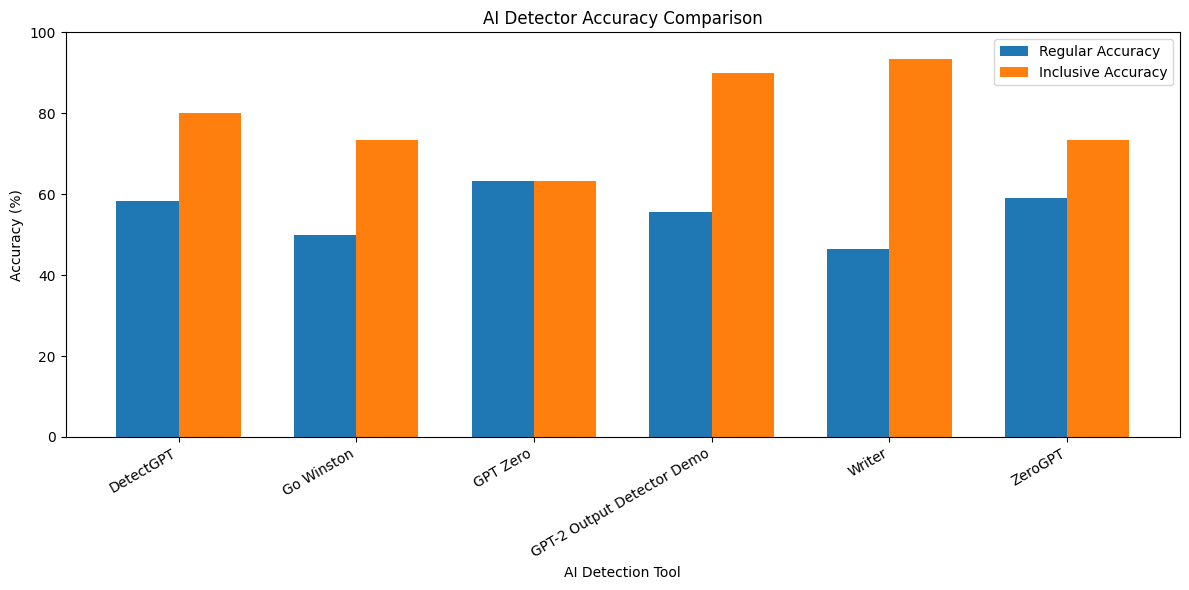

In [9]:
# Filter the dataframe for detector results
detector_df = accuracy_df[accuracy_df["result_type"] == "detector"]

# Detector accuracy comparison
plt.figure(figsize=(12, 6))

x = np.arange(len(detector_df["name"]))
width = 0.35

plt.bar(
    x - width/2,
    detector_df["regular_accuracy_pct"],
    width,
    label="Regular Accuracy"
)

plt.bar(
    x + width/2,
    detector_df["inclusive_accuracy_pct"],
    width,
    label="Inclusive Accuracy"
)

plt.title("AI Detector Accuracy Comparison")
plt.xlabel("AI Detection Tool")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(x, detector_df["name"], rotation=30, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "detector_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

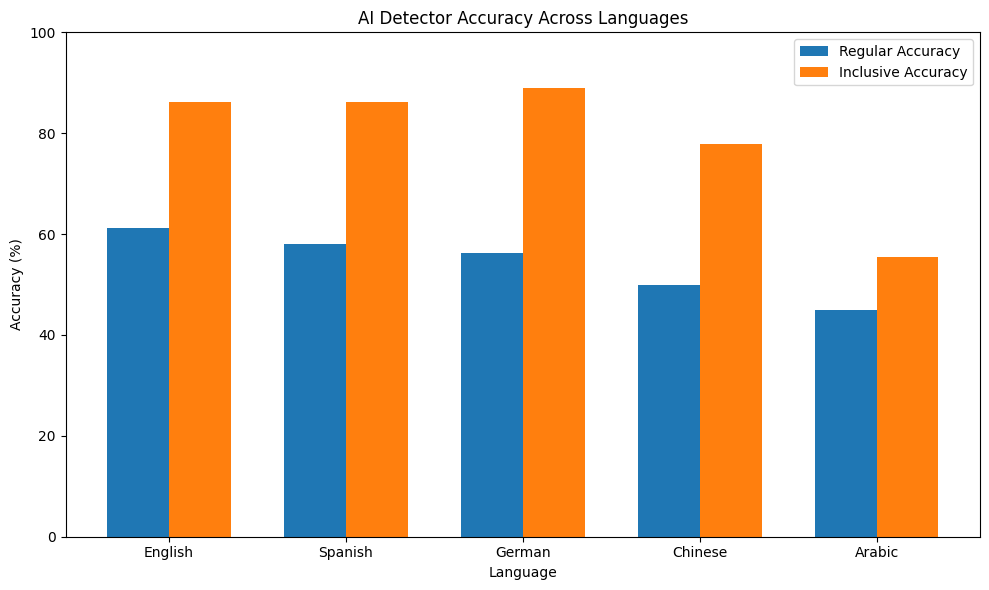

In [8]:
# Filter the dataframe for language results
lang_df = accuracy_df[accuracy_df["result_type"] == "language"]

# Language accuracy comparison
plt.figure(figsize=(10, 6))

languages = lang_df["name"]
x = np.arange(len(languages))
width = 0.35

plt.bar(
    x - width/2,
    lang_df["regular_accuracy_pct"],
    width,
    label="Regular Accuracy"
)

plt.bar(
    x + width/2,
    lang_df["inclusive_accuracy_pct"],
    width,
    label="Inclusive Accuracy"
)

plt.title("AI Detector Accuracy Across Languages")
plt.xlabel("Language")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(x, languages, rotation=0)
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "language_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

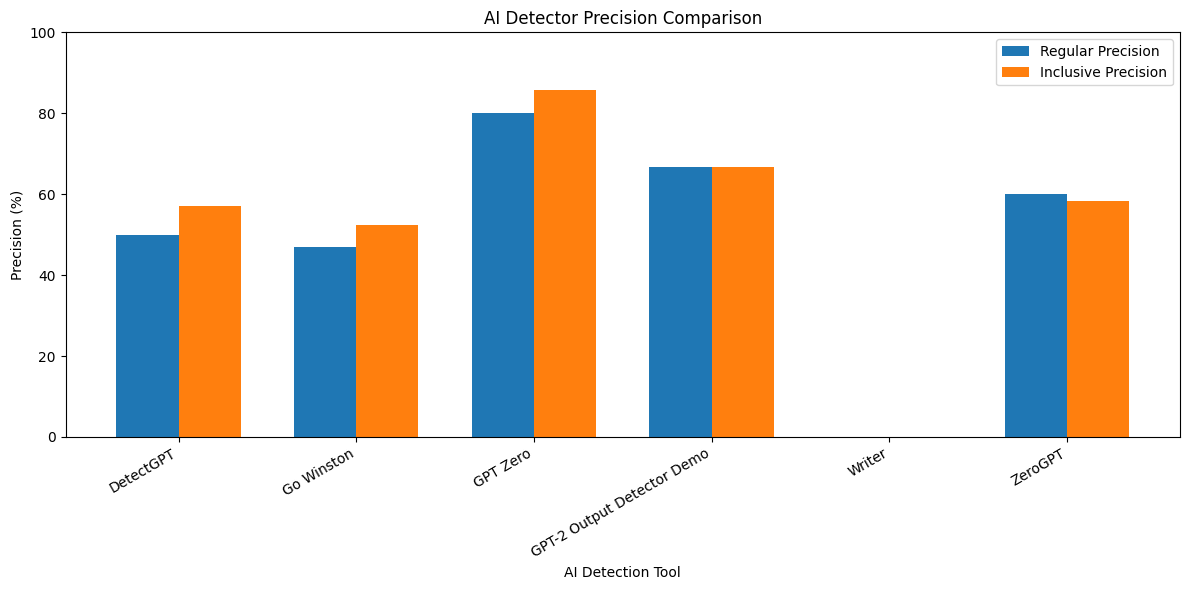

In [10]:
# Filter the precision dataframe for detector results
detector_precision_df = precision_df[precision_df["result_type"] == "detector"]

# Detector precision comparison
plt.figure(figsize=(12, 6))

x = np.arange(len(detector_precision_df["name"]))
width = 0.35

plt.bar(
    x - width/2,
    detector_precision_df["precision_pct"],
    width,
    label="Regular Precision"
)

plt.bar(
    x + width/2,
    detector_precision_df["inclusive_precision_pct"],
    width,
    label="Inclusive Precision"
)

plt.title("AI Detector Precision Comparison")
plt.xlabel("AI Detection Tool")
plt.ylabel("Precision (%)")
plt.ylim(0, 100)
plt.xticks(x, detector_precision_df["name"], rotation=30, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "detector_precision.png", dpi=300, bbox_inches="tight")
plt.show()

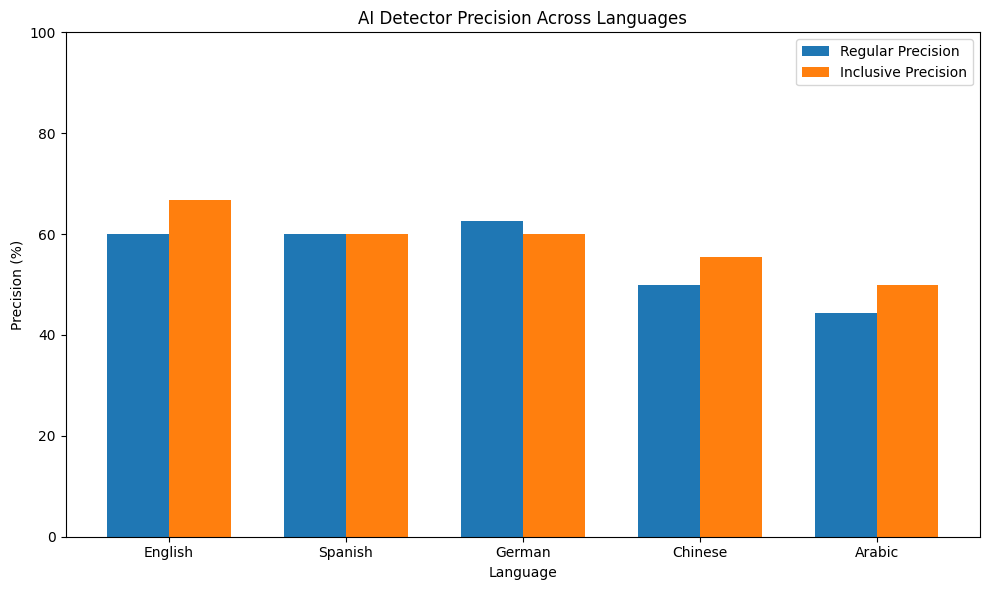

In [11]:
# Filter the precision dataframe for language results
lang_precision_df = precision_df[precision_df["result_type"] == "language"]

# Language precision comparison
plt.figure(figsize=(10, 6))

languages = lang_precision_df["name"]
x = np.arange(len(languages))
width = 0.35

plt.bar(
    x - width/2,
    lang_precision_df["precision_pct"],
    width,
    label="Regular Precision"
)

plt.bar(
    x + width/2,
    lang_precision_df["inclusive_precision_pct"],
    width,
    label="Inclusive Precision"
)

plt.title("AI Detector Precision Across Languages")
plt.xlabel("Language")
plt.ylabel("Precision (%)")
plt.ylim(0, 100)
plt.xticks(x, languages, rotation=0)
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "language_precision.png", dpi=300, bbox_inches="tight")
plt.show()

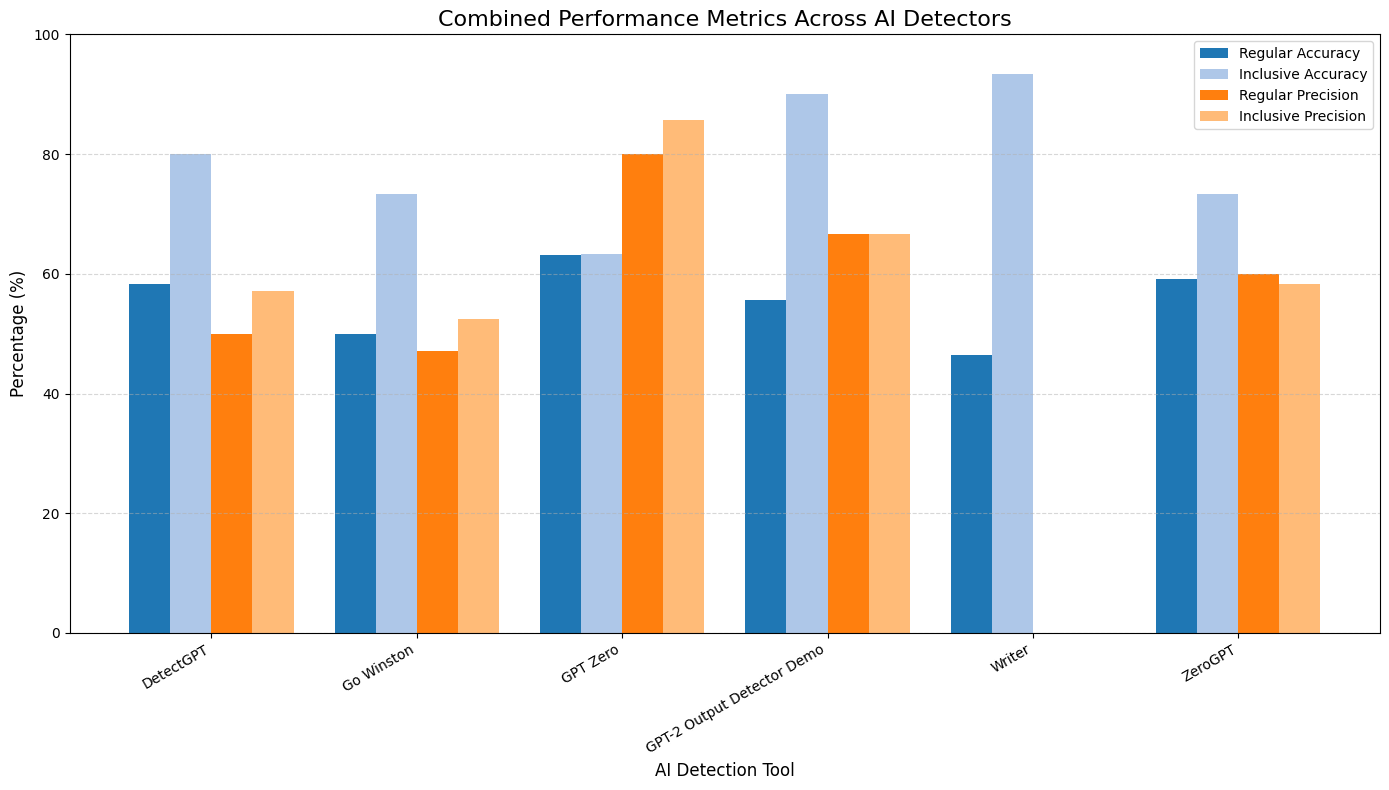

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Filter both dataframes for 'detector' type
det_acc = accuracy_df[accuracy_df['result_type'] == 'detector'][['name', 'regular_accuracy_pct', 'inclusive_accuracy_pct']]
det_prec = precision_df[precision_df['result_type'] == 'detector'][['name', 'precision_pct', 'inclusive_precision_pct']]

# Merge accuracy and precision data on detector name
combined_df = det_acc.merge(det_prec, on='name')

# Plot configuration
plt.figure(figsize=(14, 8))

detectors = combined_df['name']
x = np.arange(len(detectors))
width = 0.2

# Plot four grouped bars
plt.bar(x - 1.5*width, combined_df['regular_accuracy_pct'], width, label='Regular Accuracy', color='#1f77b4')
plt.bar(x - 0.5*width, combined_df['inclusive_accuracy_pct'], width, label='Inclusive Accuracy', color='#aec7e8')
plt.bar(x + 0.5*width, combined_df['precision_pct'], width, label='Regular Precision', color='#ff7f0e')
plt.bar(x + 1.5*width, combined_df['inclusive_precision_pct'], width, label='Inclusive Precision', color='#ffbb78')

plt.title('Combined Performance Metrics Across AI Detectors', fontsize=16)
plt.xlabel('AI Detection Tool', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.ylim(0, 100)
plt.xticks(x, detectors, rotation=30, ha='right')
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save and show combined chart
plt.savefig(FIGURES_DIR / 'combined_detector_metrics.png', dpi=300, bbox_inches='tight')
plt.show()